In [1]:
from itertools import product
import numpy as np
from scipy import linalg
import tifffile
import matplotlib.pyplot as plt
import seaborn as sns
import h5py
# import fastplotlib as fpl

In [2]:
from scipy.ndimage import gaussian_filter

In [3]:
movie = tifffile.imread("/home/kushal/caiman_data/example_movies/demoMovie.tif")[:1000,].astype(np.float32)

In [4]:
movie -= movie.min(axis=0)

In [5]:
iw = fpl.ImageWidget(movie, cmap="gnuplot2")
iw.show()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


TypeError: Figure.show() got an unexpected keyword argument 'add_widgets'

In [5]:
t, x, y = movie.shape
t, x, y

(1000, 60, 80)

In [6]:
t, xdim, ydim = movie.shape

In [7]:
n_pixels = x * y
n_timepoints = t

In [8]:
series = movie.reshape(t, x * y).T

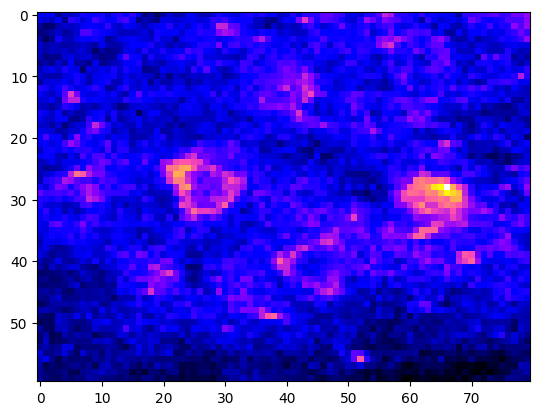

In [9]:
plt.imshow(movie.mean(axis=0), cmap="gnuplot2")

In [6]:
hm = fpl.ImageWidget(series)
hm.show()

NameError: name 'series' is not defined

In [10]:
w = 20

Ys = list()
Ps = list()
Fs = list()

for i in range(series.shape[0]):
    y = linalg.hankel(series[i, :w], series[i, w:])
    p = np.flipud(y[:int(w / 2)])
    f = y[int(w / 2):]

    Ys.append(y)
    Ps.append(p)
    Fs.append(f)

In [11]:
P_F_shape = (int(w / 2) * series.shape[0], n_timepoints - w)

P = np.zeros(P_F_shape)
F = np.zeros(P_F_shape)

for i in range(series.shape[0]):
    P[i::series.shape[0]] = Ps[i]
    F[i::series.shape[0]] = Fs[i]

H = (F @ P.T) / P.shape[1]

In [12]:
from itertools import product

In [13]:
iterator = [tuple(reversed(ixs)) for ixs in product(*[range(0, int(w / 2) * series.shape[0], series.shape[0])]*2)]
# iterator

In [14]:
Hp = np.zeros((int(w / 2)**2, series.shape[0]**2))

for row_ix, (block_row_ix, block_col_ix) in enumerate(iterator):
    Hp[row_ix] = H[block_row_ix:block_row_ix + series.shape[0], block_col_ix:block_col_ix + series.shape[0]].ravel()

In [15]:
del H

In [16]:
from scipy import sparse

In [17]:
Hp.shape

(100, 23040000)

In [18]:
u, s, v = sparse.linalg.svds(Hp, k=5)

In [19]:
u = u[:, ::-1]
s = s[::-1]
v = v[::-1]

Text(0.5, 1.0, 'V')

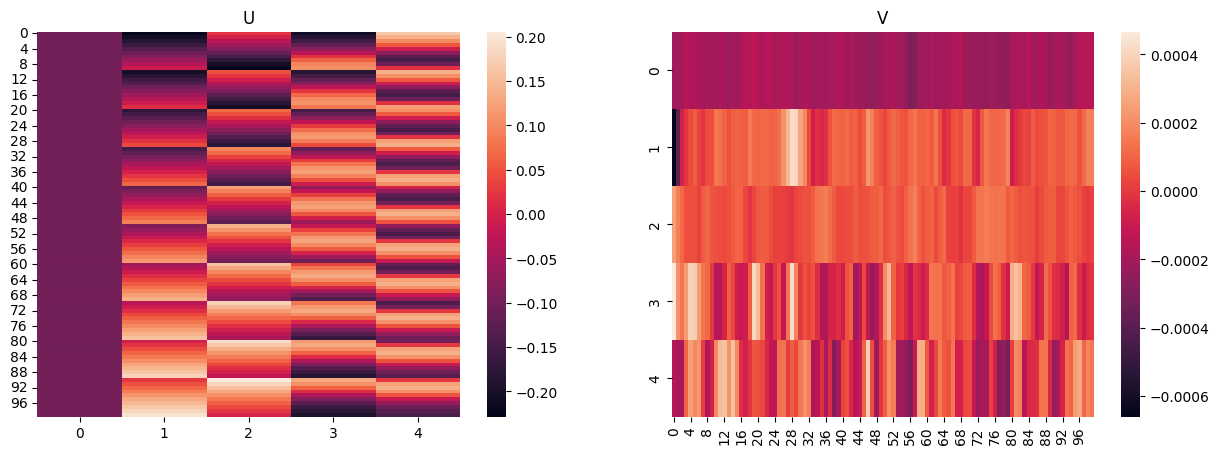

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(u, ax=axs[0])
axs[0].set_title("U")
sns.heatmap(v[:, :100], ax=axs[1])
axs[1].set_title("V")

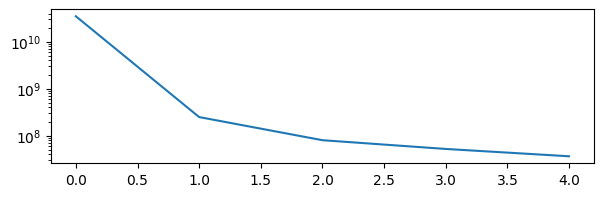

In [21]:
fig = plt.figure(figsize=(7, 2))
plt.plot(s)
plt.yscale("log")

In [22]:
s[1:].sum() / s.sum()

0.011766639483849895

In [23]:
del Hp

Text(0.5, 1.0, '$V^r$')

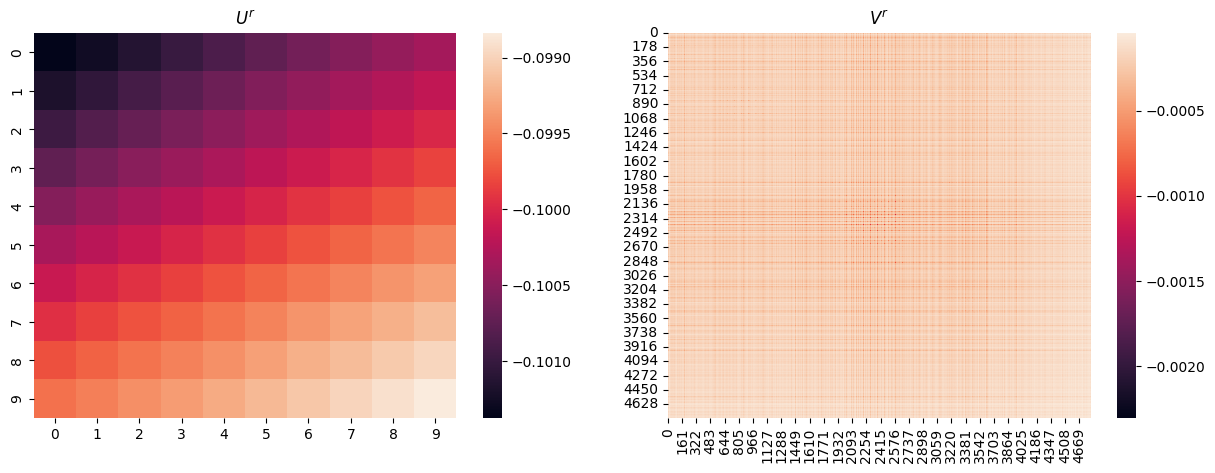

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
u_r = u[:, 0].reshape(int(w / 2), int(w / 2))
sns.heatmap(u_r, ax=axs[0])
axs[0].set_title("$U^r$")

v_r = v[0].reshape(series.shape[0], series.shape[0])
sns.heatmap(v_r, ax=axs[1])
axs[1].set_title("$V^r$")

In [28]:
from sklearn.cluster import SpectralClustering

In [65]:
sc = SpectralClustering(n_clusters=16, affinity="precomputed")
y = sc.fit_predict(np.abs(v_r))

/home/kushal/venvs/fpl/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:310: UserWarning: Array is not symmetric, and will be converted to symmetric by average with its transpose.
  adjacency = check_symmetric(adjacency)


In [66]:
y.shape

(4800,)

In [67]:
Y = y.copy()

In [76]:
bg_clusters = [3, 5, 6, 9]
for i in bg_clusters:
    y[y == i] = bg_clusters[0]

In [89]:
ys = list()
y_r = y.reshape((xdim, ydim))

for i in np.unique(y):
    ys.append(np.zeros(y_r.shape))
    ys[-1][y_r == i] = 1

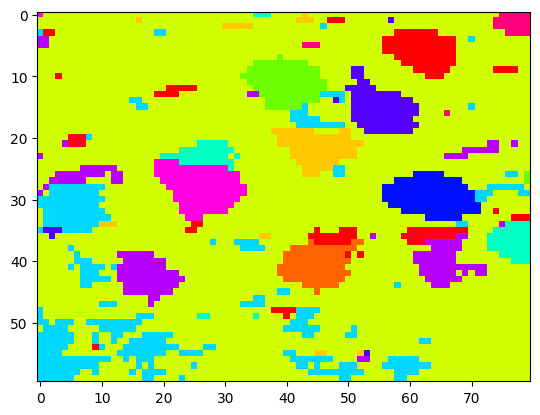

In [93]:
plt.imshow(y.reshape((xdim, ydim)), cmap="hsv")

In [69]:
import fastplotlib as fpl

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


In [75]:
[3, 5, 6, 9]

[3, 5, 6, 9]

In [94]:
iw = fpl.ImageWidget(ys)
iw.show()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

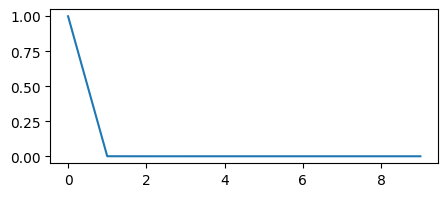

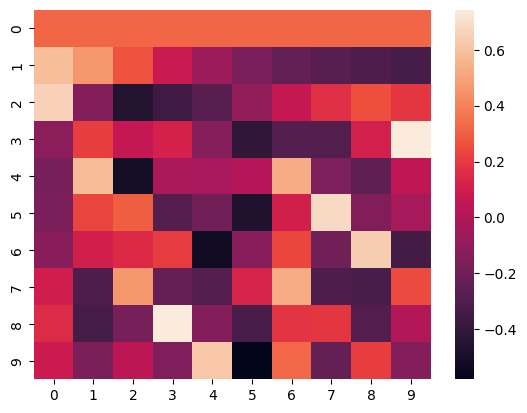

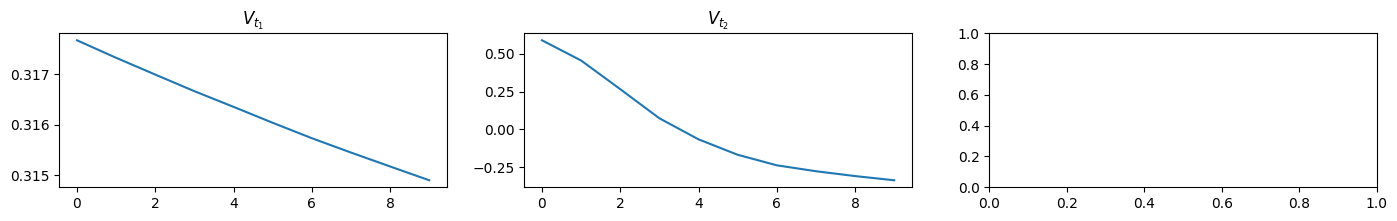

In [27]:
u_t, s_t, v_t = linalg.svd(u_r)

fig = plt.figure(figsize=(5, 2))
plt.plot(s_t)
plt.show()

sns.heatmap(v_t)
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(17, 2))

for i in range(2):
    axs[i].plot(v_t[i])
    axs[i].set_title(f"$V_{{t_{i + 1}}}$")
    
plt.show()

In [28]:
from sklearn.decomposition import SparsePCA

In [29]:
u_s, s_s, v_s = linalg.svd(v_r)

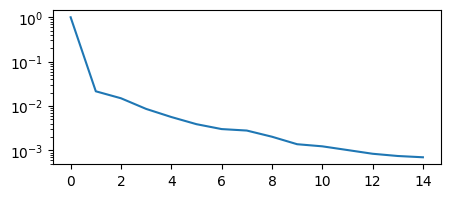

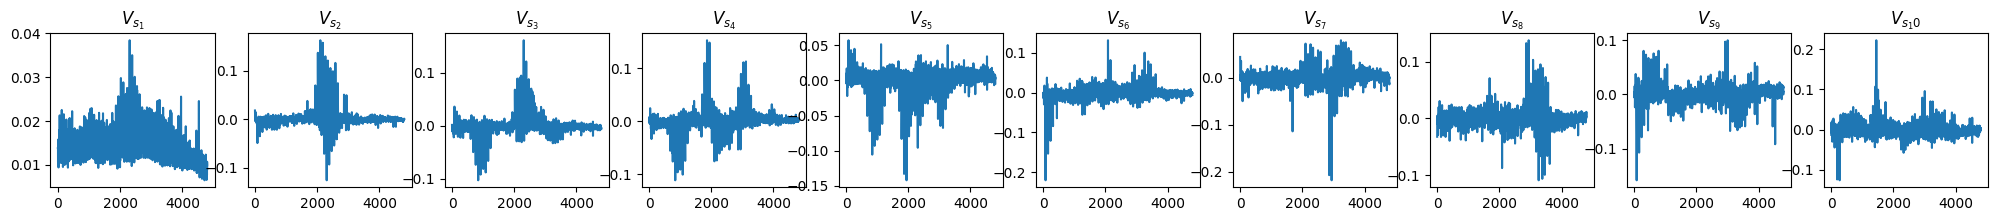

In [30]:
n_components = 10

fig = plt.figure(figsize=(5, 2))
plt.plot(s_s[:15])
plt.yscale("log")

fig, axs = plt.subplots(1, n_components, figsize=(25, 2))

for i in range(n_components):
    axs[i].plot(v_s[i])
    axs[i].set_title(f"$V_{{s_{i + 1}}}$")

plt.show()

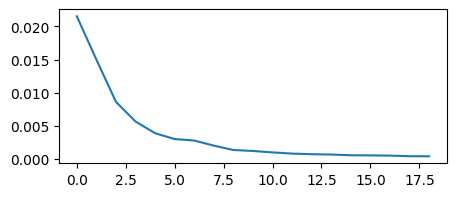

In [31]:
fig = plt.figure(figsize=(5, 2))
plt.plot(s_s[1:20])
# plt.yscale("log")
# plt.xscale("log")

In [32]:
images = [img for img in v_s[:20].reshape(20, xdim, ydim)]

In [64]:
iw_raw_c = fpl.ImageWidget(images, histogram_widget=False, cmap="bwr")
iw_raw_c.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [34]:
from sklearn.decomposition import FastICA

In [35]:
ica = FastICA(n_components=10)
u_ica = ica.fit_transform(v_r)
v_ica = ica.components_

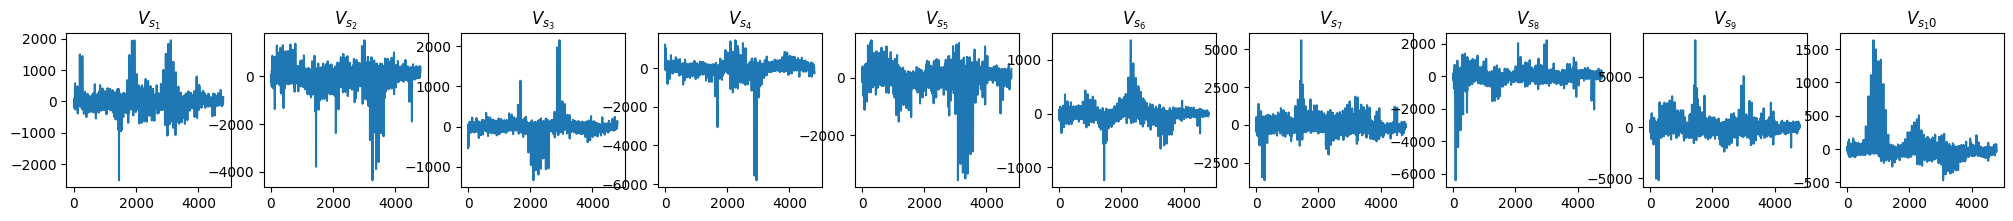

In [36]:
fig, axs = plt.subplots(1, 10, figsize=(25, 2))

for i in range(10):
    axs[i].plot(v_ica[i])
    axs[i].set_title(f"$V_{{s_{i + 1}}}$")

plt.show()

In [37]:
images = [img for img in v_ica[:10].reshape(10, xdim, ydim)]

In [38]:
iw_ica = fpl.ImageWidget(images, histogram_widget=False, cmap="bwr")
iw_ica.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

<Axes: >

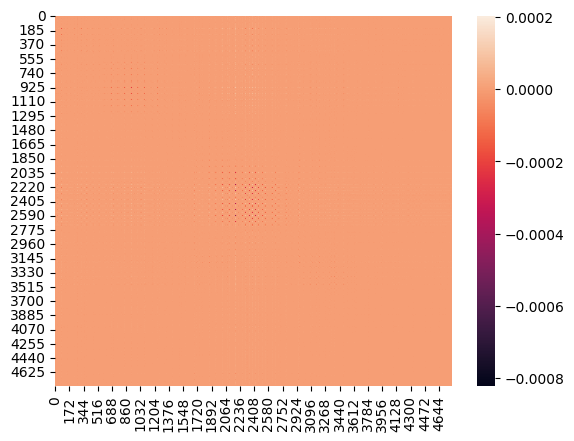

In [39]:
s_s_trunc = np.diag(s_s)
s_s_trunc[0] = 0

v_r_trunc = u_s @ s_s_trunc @ v_s
sns.heatmap(v_r_trunc)

In [68]:
pca = SparsePCA(n_components=20, alpha=10e-10, n_jobs=16, max_iter=10, method="cd")

u_s_sparse = pca.fit_transform(v_r_trunc)
v_s_sparse = pca.components_

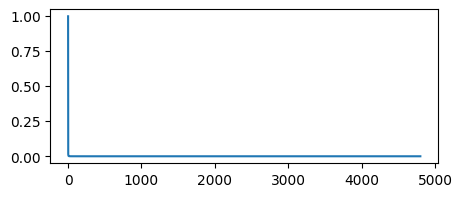

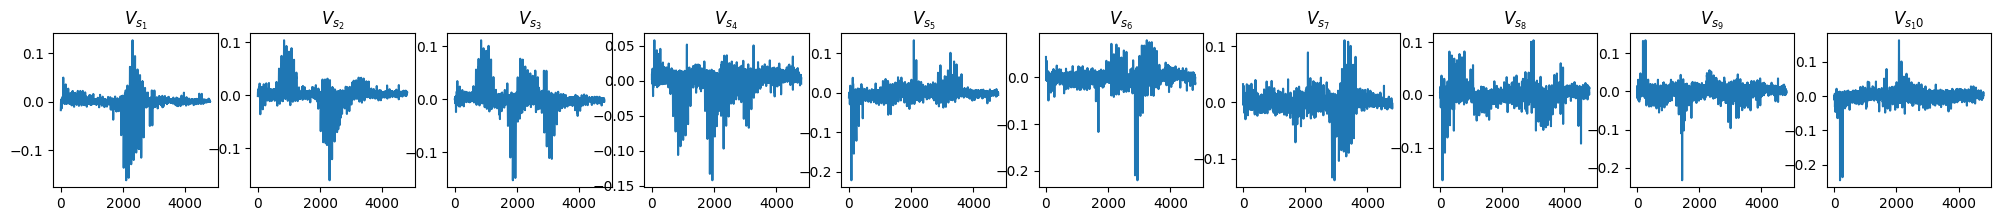

In [69]:
fig = plt.figure(figsize=(5, 2))
plt.plot(s_s)

fig, axs = plt.subplots(1, n_components, figsize=(25, 2))

for i in range(n_components):
    axs[i].plot(v_s_sparse[i])
    axs[i].set_title(f"$V_{{s_{i + 1}}}$")

plt.show()

In [70]:
images = [img for img in v_s_sparse[:10].reshape(10, xdim, ydim)]

In [71]:
iw_c = fpl.ImageWidget(images, histogram_widget=False, cmap="bwr")
iw_c.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [60]:
ica = FastICA(n_components=10)
u_ica = ica.fit_transform(v_r_trunc)
v_ica = ica.components_

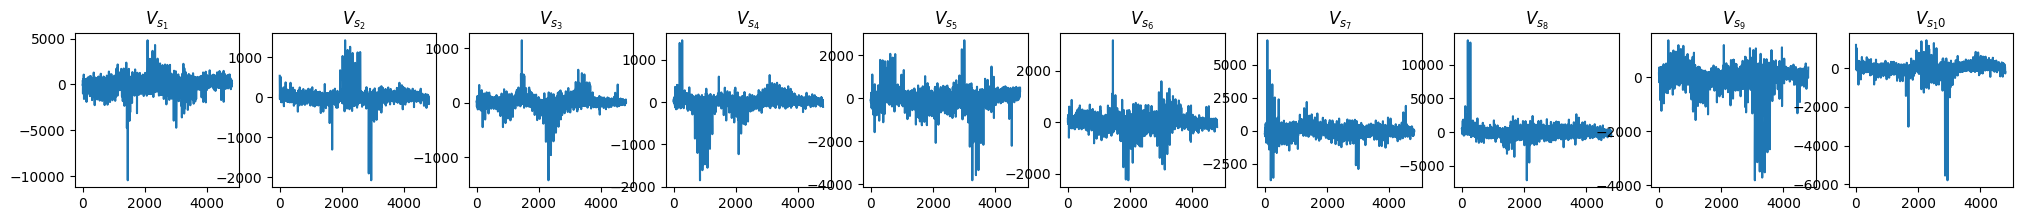

In [61]:
fig, axs = plt.subplots(1, 10, figsize=(25, 2))

for i in range(10):
    axs[i].plot(v_ica[i])
    axs[i].set_title(f"$V_{{s_{i + 1}}}$")

plt.show()

In [62]:
images = [img for img in v_ica[:10].reshape(10, xdim, ydim)]

In [63]:
iw_ica = fpl.ImageWidget(images, histogram_widget=False, cmap="bwr")
iw_ica.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

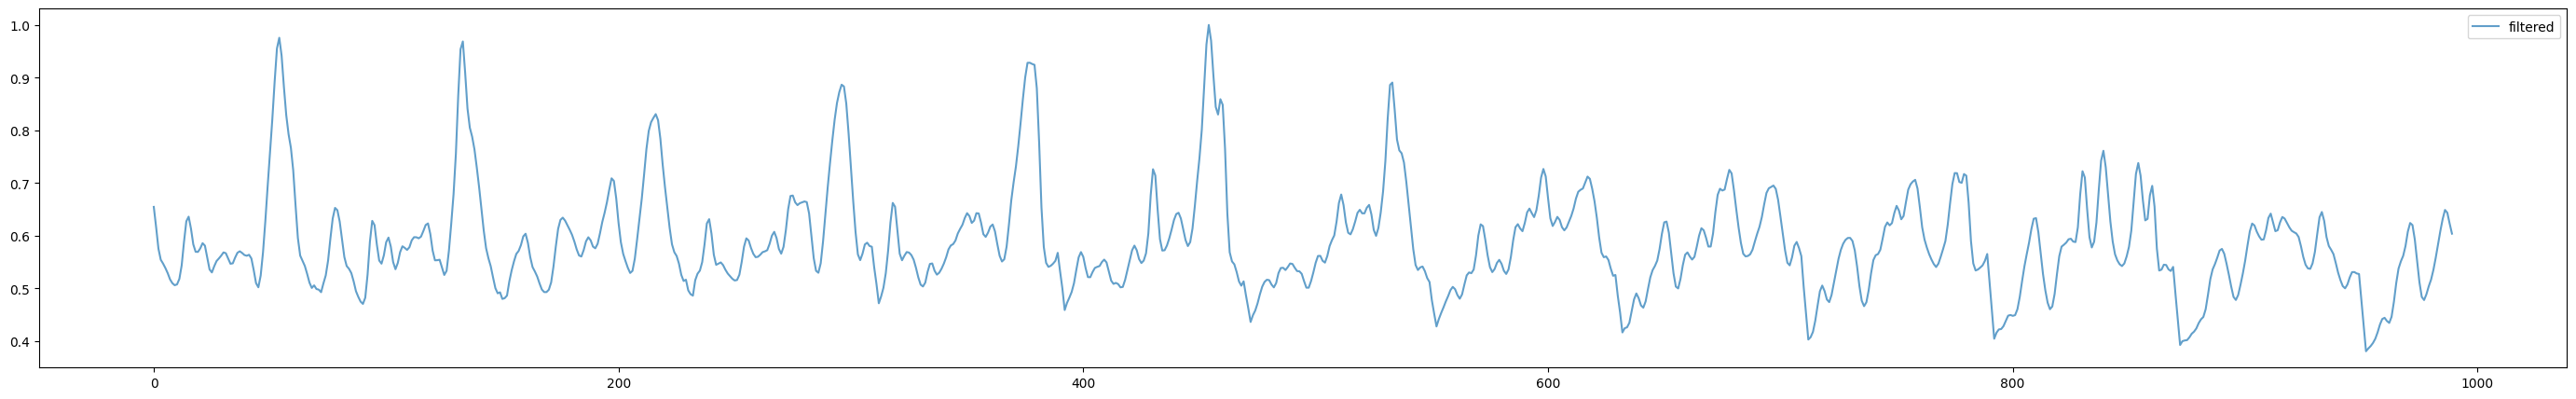

In [77]:
filtered = np.zeros(shape=(n_timepoints - int(w / 2)))
filtered[int(w / 2):] = filts[2] @ P
filtered = -filtered

filtered -= filtered.min()
filtered /= filtered.max()

indices = slice(10, 1_000)
fig = plt.figure(figsize=(35, 5))
plt.plot(filtered[indices], label="filtered", alpha=0.7)
plt.legend()
plt.show()

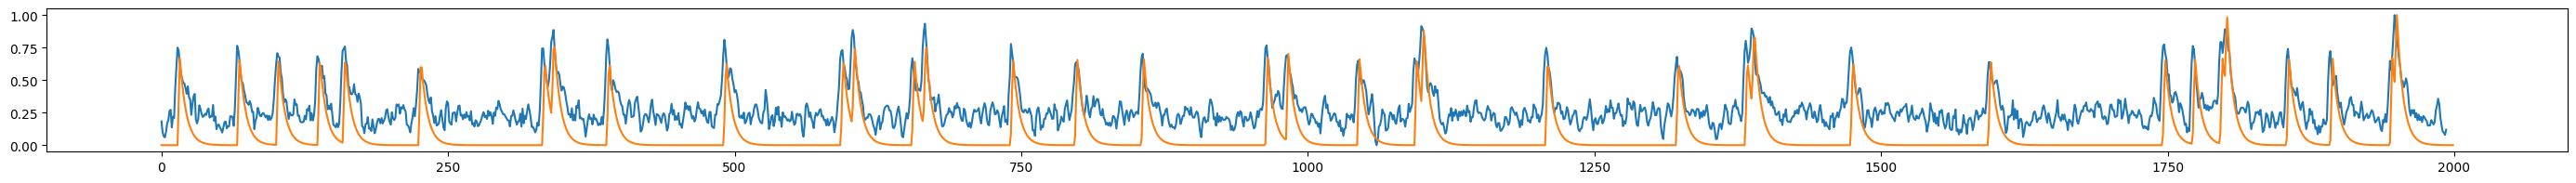

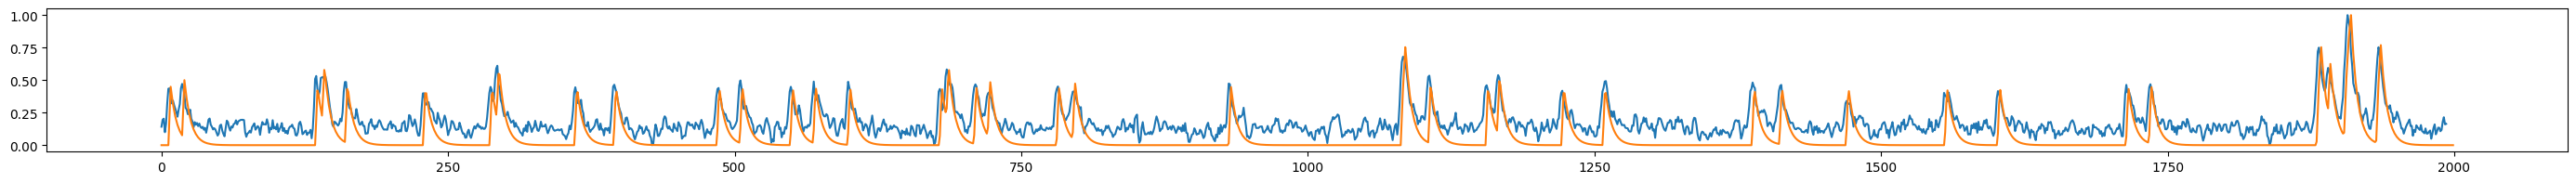

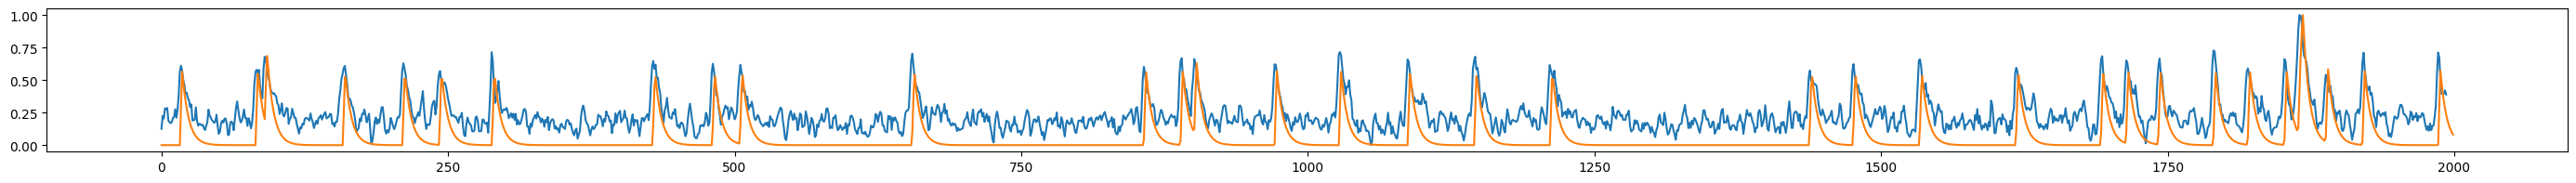

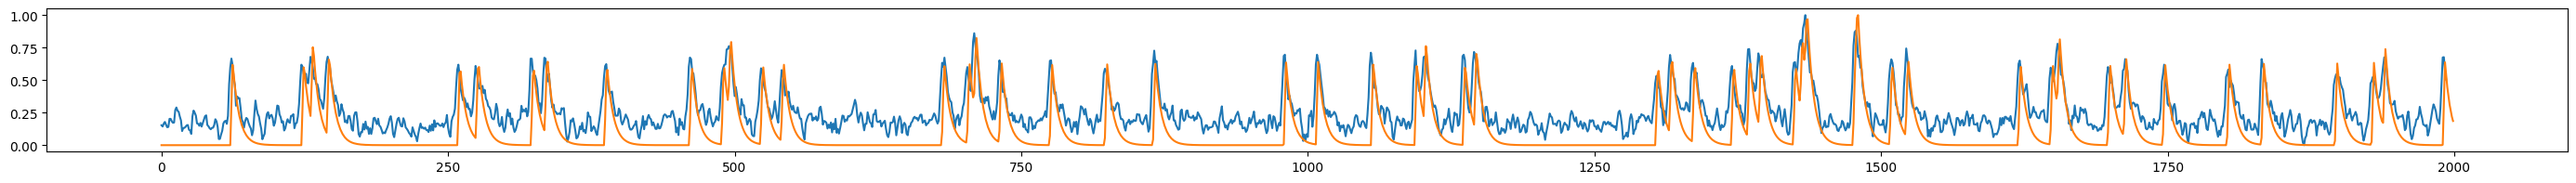

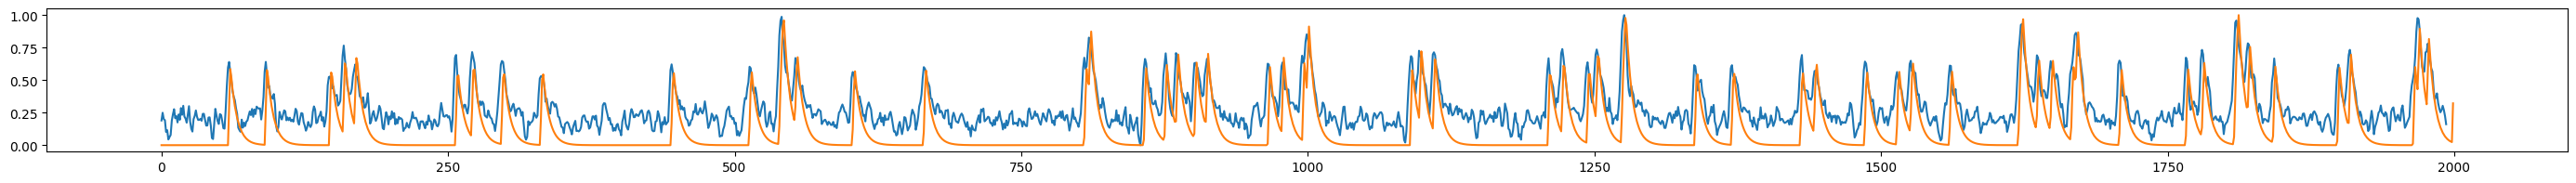

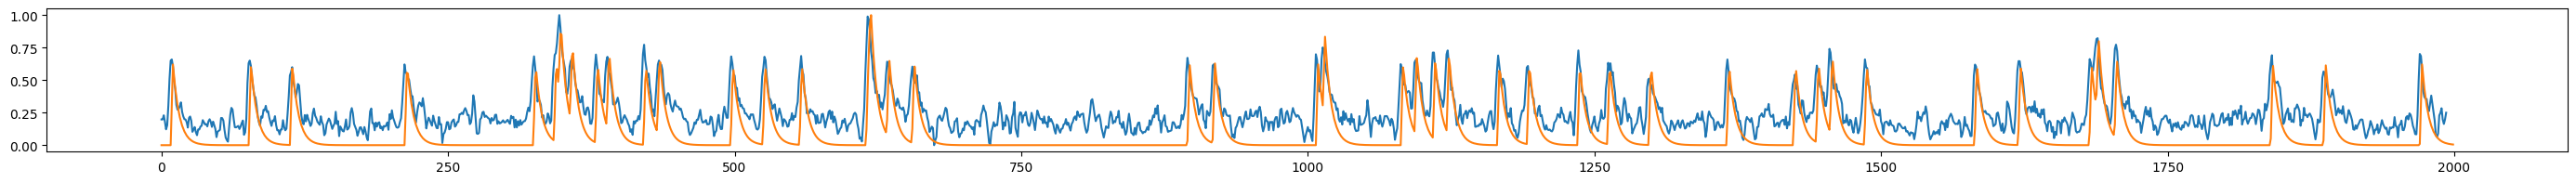

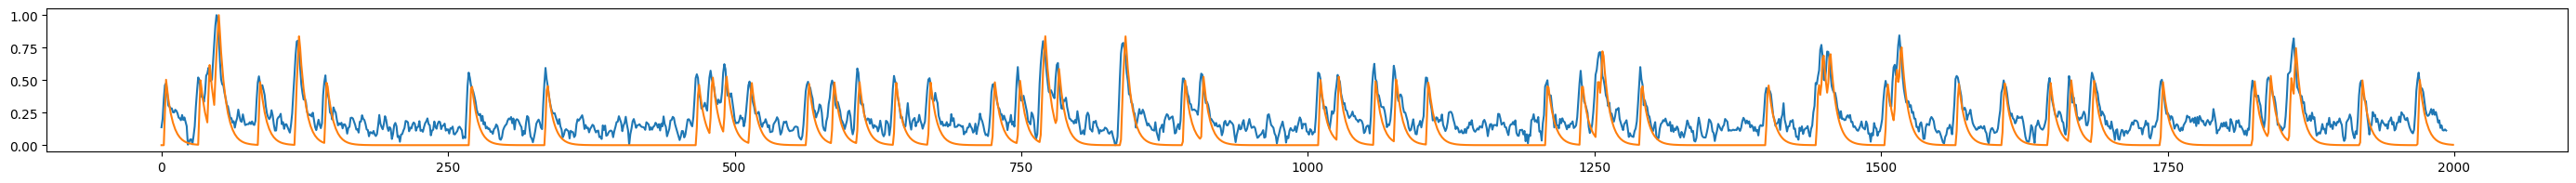

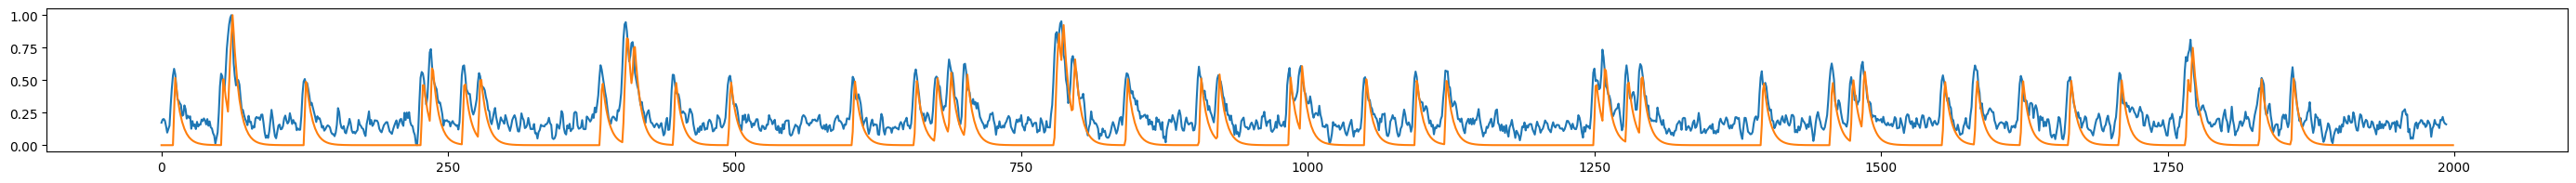

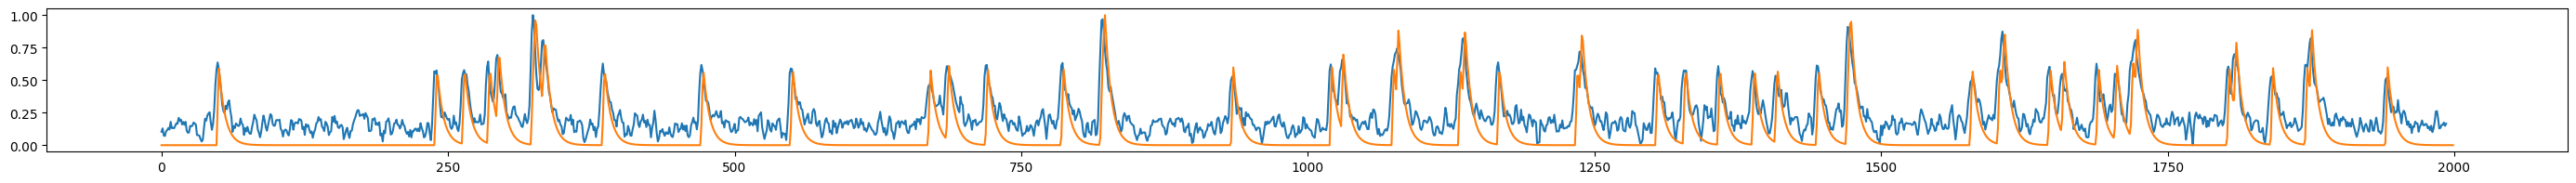

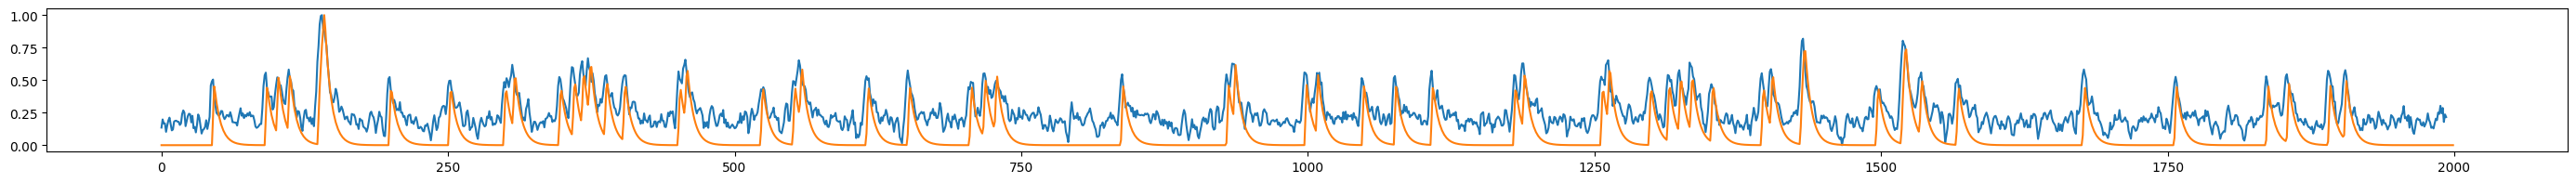

In [46]:
for i in range(n_components):
    filtered = filts[component_ixs[i]] @ P
    
    filtered -= filtered.min()
    filtered /= filtered.max()
    
    fig = plt.figure(figsize=(35, 2))
    plt.plot(filtered)
    plt.plot(clean[i] / clean[i].max())
    plt.show()

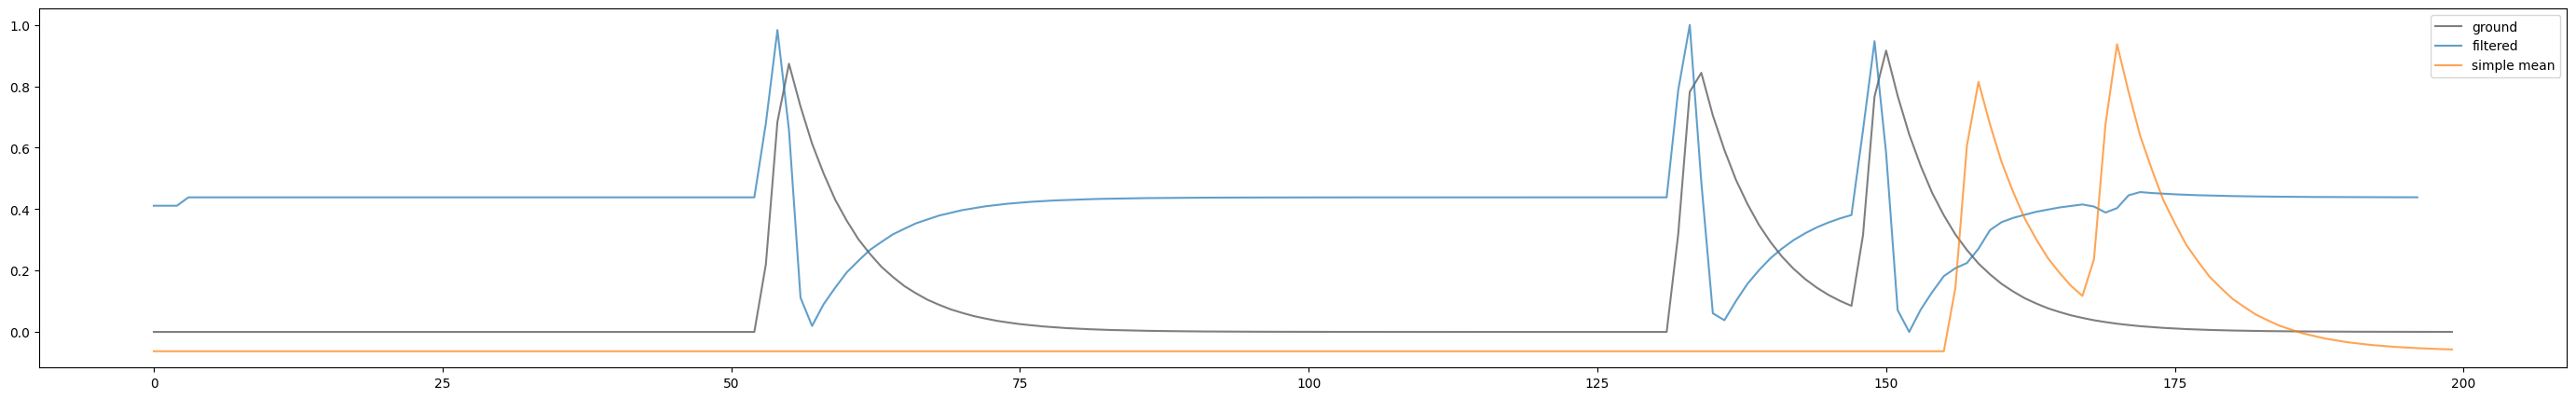

In [211]:
filtered = np.zeros(shape=(n_timepoints - int(w / 2)))
filtered[int(w / 2):] = filt2 @ P


filtered -= filtered.min()
filtered /= filtered.max()

indices = slice(0, 500)
fig = plt.figure(figsize=(35, 5))
plt.plot(clean[0, indices] / clean.max(), label="ground", alpha=0.5, c="k")
plt.plot(filtered[indices], label="filtered", alpha=0.7)
plt.plot(series[4:-1].mean(axis=0)[indices] / clean.max(), alpha=0.7, label="simple mean")
plt.legend()
plt.show()